# 전략 슬라이드 EDA — 슬라이드 17 · 20 · 22 · 26 근거 데이터

**목적:** 발표자료 각 전략 슬라이드 앞에 삽입할 EDA 현황 차트 생성  

| 차트 | 삽입 위치 | 가설 | 내용 |
|---|---|---|---|
| EDA 1 | 슬라이드 17 앞 | H3 | 사진 수 구간별 리스팅 분포 · RevPAR |
| EDA 2 | 슬라이드 20 앞 | H4 | 최소숙박일 구간별 RevPAR · 점유율 |
| EDA 2b | 슬라이드 20 앞 | — | 평점 구간별 RevPAR · 점유율 |
| EDA 3 | 슬라이드 22 앞 | H5 | 추가인원요금 도입 현황 · 규모별 RevPAR |
| EDA 4 | 슬라이드 26 앞 | — | 자치구·군집별 RevPAR 분포 |

**분석 대상:** Active + Operating (n=14,399)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

BASE      = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
FEATURES  = BASE / 'data' / 'processed' / 'seoul_airbnb_features.csv'
CLUSTERED = BASE / 'data' / 'processed' / 'district_clustered.csv'
REPORTS   = BASE / 'reports'
REPORTS.mkdir(exist_ok=True)

# 공통 격자 설정
GY = dict(axis='y', linestyle='--', alpha=0.35, color='#AAAAAA', zorder=0)
GX = dict(axis='x', linestyle='--', alpha=0.35, color='#AAAAAA', zorder=0)

df = pd.read_csv(FEATURES)
ao = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()

print(f'분석 대상: {len(ao):,}건 (Active+Operating)')

분석 대상: 14,399건 (Active+Operating)


---
## EDA 1 — H3 사진 수 현황 (슬라이드 17 앞)

**질문:** 실제로 사진 수가 적은 숙소가 얼마나 되는가? 사진 구간별 RevPAR 차이는?  
**전략 연결:** → 21~35장 최적 구간 확보 전략의 데이터 근거

In [2]:
# ── 사진 수 구간 정의 (photos_tier 컬럼 활용)
tier_order = ['하', '중하', '중상', '상']
tier_label = {'하': '≤10장', '중하': '11~20장', '중상': '21~35장', '상': '36장+'}

tier_n   = ao.groupby('photos_tier').size().reindex(tier_order)
tier_rev = ao.groupby('photos_tier')['ttm_revpar'].median().reindex(tier_order)

print('=== 사진 수 구간별 현황 ===')
summary = pd.DataFrame({
    '구간': [tier_label[t] for t in tier_order],
    '리스팅 수': tier_n.values,
    '비중(%)': (tier_n.values / tier_n.sum() * 100).round(1),
    'TTM RevPAR 중위값(₩)': tier_rev.values.astype(int),
})
print(summary.to_string(index=False))
print(f'\n최고 RevPAR 구간: {tier_label[tier_rev.idxmax()]} (₩{tier_rev.max():,.0f})')
print(f'최저 RevPAR 구간: {tier_label[tier_rev.idxmin()]} (₩{tier_rev.min():,.0f})')
print(f'RevPAR 배율 (상/하): {tier_rev["상"]/tier_rev["하"]:.2f}×')

=== 사진 수 구간별 현황 ===
    구간  리스팅 수  비중(%)  TTM RevPAR 중위값(₩)
  ≤10장   2386   16.6              24994
11~20장   3448   23.9              39750
21~35장   3726   25.9              50147
  36장+   4839   33.6              69464

최고 RevPAR 구간: 36장+ (₩69,465)
최저 RevPAR 구간: ≤10장 (₩24,994)
RevPAR 배율 (상/하): 2.78×


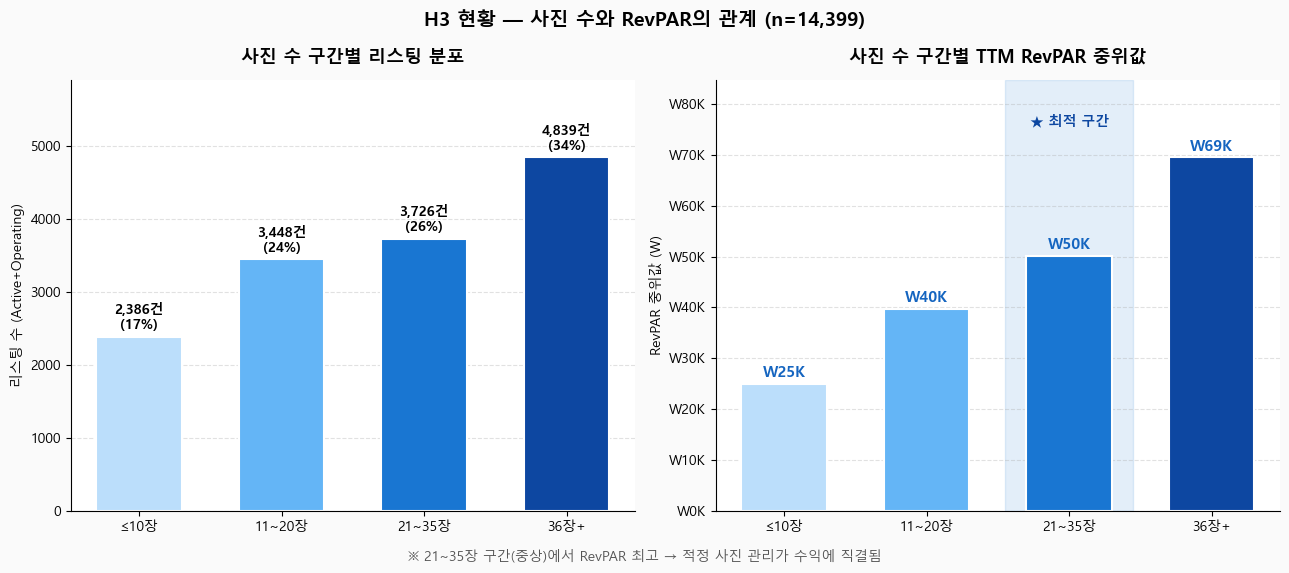

저장 완료: reports/fig_eda_slide17_photos.png


In [3]:
tier_color = {'하': '#BBDEFB', '중하': '#64B5F6', '중상': '#1976D2', '상': '#0D47A1'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.patch.set_facecolor('#FAFAFA')

# ① 리스팅 수 분포
ax = axes[0]
ax.grid(**GY); ax.set_axisbelow(True)
bars = ax.bar(
    [tier_label[t] for t in tier_order], tier_n.values,
    color=[tier_color[t] for t in tier_order],
    width=0.6, edgecolor='white', linewidth=1.5
)
for bar, n in zip(bars, tier_n.values):
    pct = n / tier_n.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 60,
            f'{n:,}건\n({pct:.0f}%)', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('사진 수 구간별 리스팅 분포', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('리스팅 수 (Active+Operating)', fontsize=10)
ax.set_ylim(0, tier_n.max() * 1.22)
ax.spines[['top', 'right']].set_visible(False)

# ② RevPAR 중위값
ax2 = axes[1]
ax2.grid(**GY); ax2.set_axisbelow(True)
bars2 = ax2.bar(
    [tier_label[t] for t in tier_order], tier_rev.values,
    color=[tier_color[t] for t in tier_order],
    width=0.6, edgecolor='white', linewidth=1.5
)
for bar, v in zip(bars2, tier_rev.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
             f'W{v/1000:.0f}K', ha='center', va='bottom',
             fontsize=11, fontweight='bold', color='#1565C0')
opt_idx = tier_order.index('중상')
ax2.axvspan(opt_idx - 0.45, opt_idx + 0.45, alpha=0.12, color='#1976D2', zorder=0)
ax2.text(opt_idx, tier_rev.max() * 1.09, '★ 최적 구간',
         ha='center', fontsize=10, color='#0D47A1', fontweight='bold')
ax2.set_title('사진 수 구간별 TTM RevPAR 중위값', fontsize=13, fontweight='bold', pad=12)
ax2.set_ylabel('RevPAR 중위값 (W)', fontsize=10)
ax2.set_ylim(0, tier_rev.max() * 1.22)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('H3 현황 — 사진 수와 RevPAR의 관계 (n=14,399)', fontsize=14, fontweight='bold')
fig.text(0.5, -0.02,
    '※ 21~35장 구간(중상)에서 RevPAR 최고 → 적정 사진 관리가 수익에 직결됨',
    ha='center', fontsize=10, color='#555', style='italic')

plt.tight_layout()
fig.savefig(REPORTS / 'fig_eda_slide17_photos.png', dpi=130, bbox_inches='tight', facecolor='#FAFAFA')
plt.show()
print('저장 완료: reports/fig_eda_slide17_photos.png')

---
## EDA 2 — H4 최소숙박일 현황 (슬라이드 20 앞)

**질문:** 최소숙박일 설정이 어떻게 분포하는가? RevPAR와 점유율은 구간별로 어떻게 다른가?  
**전략 연결:** → RevPAR 최적(2~3박) vs 점유율 최적(4~7박) 불일치 → 목표에 따른 설정 권장

In [4]:
def mn_bucket(n):
    if n <= 0:   return '0박(미설정)'
    elif n == 1: return '1박'
    elif n <= 3: return '2~3박'
    elif n <= 7: return '4~7박'
    else:        return '8박+'

ao['mn_bucket'] = ao['min_nights'].apply(mn_bucket)
bucket_order = ['1박', '2~3박', '4~7박', '8박+']
ao_valid = ao[ao['min_nights'] >= 1].copy()
ao_valid['mn_bucket'] = ao_valid['min_nights'].apply(mn_bucket)

n_cnt   = ao_valid.groupby('mn_bucket').size().reindex(bucket_order)
rev_med = ao_valid.groupby('mn_bucket')['ttm_revpar'].median().reindex(bucket_order)
occ_med = ao_valid.groupby('mn_bucket')['ttm_occupancy'].median().reindex(bucket_order) * 100

print('=== 최소숙박일 구간별 현황 ===')
summary2 = pd.DataFrame({
    '구간': bucket_order,
    '리스팅 수': n_cnt.values,
    '비중(%)': (n_cnt.values / n_cnt.sum() * 100).round(1),
    'RevPAR 중위(₩)': rev_med.values.astype(int),
    '점유율 중위(%)': occ_med.values.round(1),
})
print(summary2.to_string(index=False))
print(f'\nRevPAR 최적 구간: {rev_med.idxmax()} (₩{rev_med.max():,.0f})')
print(f'점유율 최적 구간: {occ_med.idxmax()} ({occ_med.max():.1f}%)')

=== 최소숙박일 구간별 현황 ===
  구간  리스팅 수  비중(%)  RevPAR 중위(₩)  점유율 중위(%)
  1박   5351   42.2         48739       48.8
2~3박   4239   33.5         56199       58.1
4~7박   2132   16.8         49681       59.7
 8박+    949    7.5         21297       41.6

RevPAR 최적 구간: 2~3박 (₩56,200)
점유율 최적 구간: 4~7박 (59.7%)


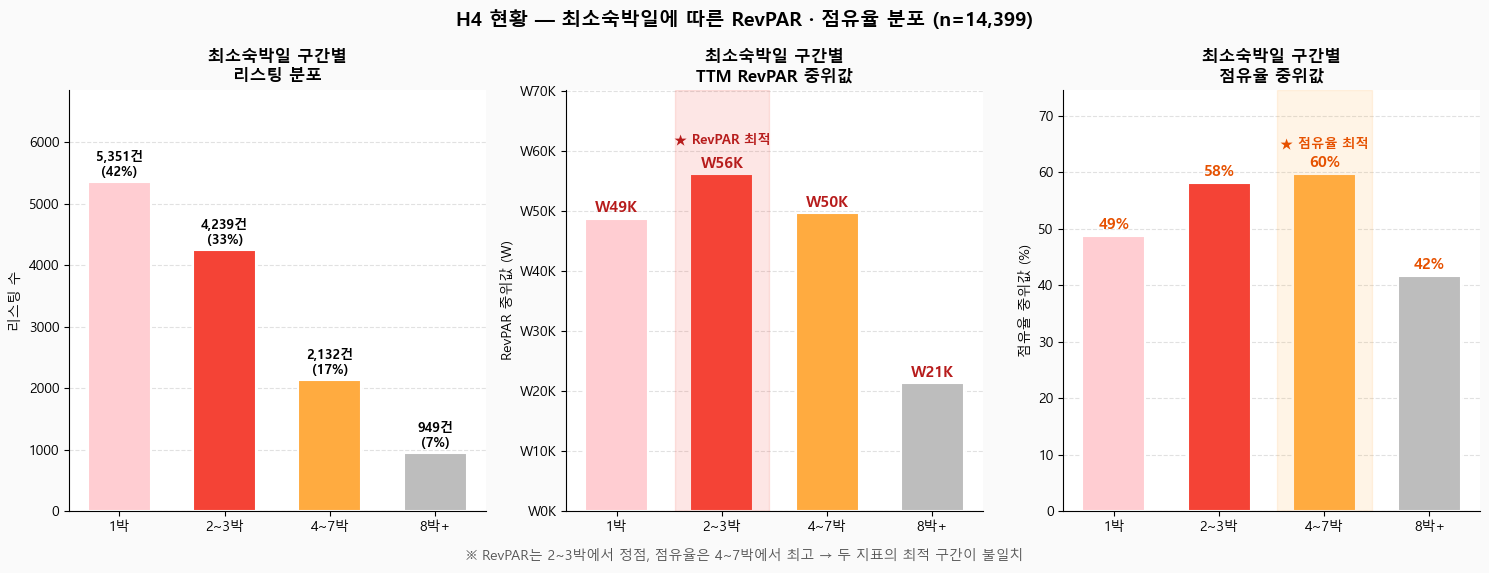

저장 완료: reports/fig_eda_slide20_minnights.png


In [5]:
bucket_colors = {'1박': '#FFCDD2', '2~3박': '#F44336', '4~7박': '#FFAB40', '8박+': '#BDBDBD'}
colors = [bucket_colors[b] for b in bucket_order]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
fig.patch.set_facecolor('#FAFAFA')

# ① 리스팅 수
ax = axes[0]
ax.grid(**GY); ax.set_axisbelow(True)
bars = ax.bar(bucket_order, n_cnt.values, color=colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, n in zip(bars, n_cnt.values):
    pct = n / n_cnt.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{n:,}건\n({pct:.0f}%)', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax.set_title('최소숙박일 구간별\n리스팅 분포', fontsize=12, fontweight='bold')
ax.set_ylabel('리스팅 수', fontsize=10)
ax.set_ylim(0, n_cnt.max() * 1.28)
ax.spines[['top', 'right']].set_visible(False)

# ② RevPAR 중위값
ax2 = axes[1]
ax2.grid(**GY); ax2.set_axisbelow(True)
bars2 = ax2.bar(bucket_order, rev_med.values, color=colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, v in zip(bars2, rev_med.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
             f'W{v/1000:.0f}K', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#B71C1C')
opt_rev_idx = list(bucket_order).index(rev_med.idxmax())
ax2.axvspan(opt_rev_idx - 0.45, opt_rev_idx + 0.45, alpha=0.13, color='#F44336', zorder=1)
ax2.text(opt_rev_idx, rev_med.max() * 1.09, '★ RevPAR 최적',
         ha='center', fontsize=9.5, color='#B71C1C', fontweight='bold')
ax2.set_title('최소숙박일 구간별\nTTM RevPAR 중위값', fontsize=12, fontweight='bold')
ax2.set_ylabel('RevPAR 중위값 (W)', fontsize=10)
ax2.set_ylim(0, rev_med.max() * 1.25)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax2.spines[['top', 'right']].set_visible(False)

# ③ 점유율 중위값
ax3 = axes[2]
ax3.grid(**GY); ax3.set_axisbelow(True)
bars3 = ax3.bar(bucket_order, occ_med.values, color=colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, v in zip(bars3, occ_med.values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{v:.0f}%', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#E65100')
opt_occ_idx = list(bucket_order).index(occ_med.idxmax())
ax3.axvspan(opt_occ_idx - 0.45, opt_occ_idx + 0.45, alpha=0.13, color='#FFAB40', zorder=1)
ax3.text(opt_occ_idx, occ_med.max() * 1.08, '★ 점유율 최적',
         ha='center', fontsize=9.5, color='#E65100', fontweight='bold')
ax3.set_title('최소숙박일 구간별\n점유율 중위값', fontsize=12, fontweight='bold')
ax3.set_ylabel('점유율 중위값 (%)', fontsize=10)
ax3.set_ylim(0, occ_med.max() * 1.25)
ax3.spines[['top', 'right']].set_visible(False)

fig.suptitle('H4 현황 — 최소숙박일에 따른 RevPAR · 점유율 분포 (n=14,399)', fontsize=14, fontweight='bold')
fig.text(0.5, -0.02,
    '※ RevPAR는 2~3박에서 정점, 점유율은 4~7박에서 최고 → 두 지표의 최적 구간이 불일치',
    ha='center', fontsize=10, color='#555', style='italic')

plt.tight_layout()
fig.savefig(REPORTS / 'fig_eda_slide20_minnights.png', dpi=130, bbox_inches='tight', facecolor='#FAFAFA')
plt.show()
print('저장 완료: reports/fig_eda_slide20_minnights.png')

---
## EDA 2b — 평점 현황 (슬라이드 20 앞)

**질문:** 평점 구간별로 리스팅 분포, RevPAR, 점유율은 어떻게 다른가?  
**전략 연결:** → 평점 4.8 이상 유지가 RevPAR와 직결되는 데이터 근거

In [6]:
# ── 평점 구간 정의
ao_r = ao[(ao['rating_overall'].notna()) & (ao['rating_overall'] >= 3.0)].copy()
rate_order  = ['4.0미만', '4.0~4.4', '4.5~4.7', '4.8~5.0']
rate_colors = ['#EF9A9A', '#EF5350', '#E53935', '#B71C1C']

def rate_bucket(r):
    if r < 4.0: return '4.0미만'
    elif r < 4.5: return '4.0~4.4'
    elif r < 4.8: return '4.5~4.7'
    else:        return '4.8~5.0'

ao_r['rate_grp'] = ao_r['rating_overall'].apply(rate_bucket)
rate_n   = ao_r.groupby('rate_grp').size().reindex(rate_order).fillna(0).astype(int)
rate_rev = ao_r.groupby('rate_grp')['ttm_revpar'].median().reindex(rate_order)
rate_occ = ao_r.groupby('rate_grp')['ttm_occupancy'].median().reindex(rate_order) * 100

print('=== 평점 구간별 현황 ===')
summary_r = pd.DataFrame({
    '구간': rate_order,
    '리스팅 수': rate_n.values,
    '비중(%)': (rate_n.values / rate_n.sum() * 100).round(1),
    'TTM RevPAR 중위값(W)': rate_rev.values.astype(int),
    '점유율 중위(%)': rate_occ.values.round(1),
})
print(summary_r.to_string(index=False))
print(f'\n최고 RevPAR 구간: {rate_rev.idxmax()} (W{rate_rev.max():,.0f})')
high_pct = rate_n['4.8~5.0'] / rate_n.sum() * 100
print(f'최고평점(4.8~5.0) 비율: {high_pct:.0f}%')

=== 평점 구간별 현황 ===
     구간  리스팅 수  비중(%)  TTM RevPAR 중위값(W)  점유율 중위(%)
  4.0미만    239    1.7              14185       20.0
4.0~4.4   1321    9.6              22225       32.9
4.5~4.7   4326   31.4              42815       48.8
4.8~5.0   7905   57.3              61901       59.2

최고 RevPAR 구간: 4.8~5.0 (W61,901)
최고평점(4.8~5.0) 비율: 57%


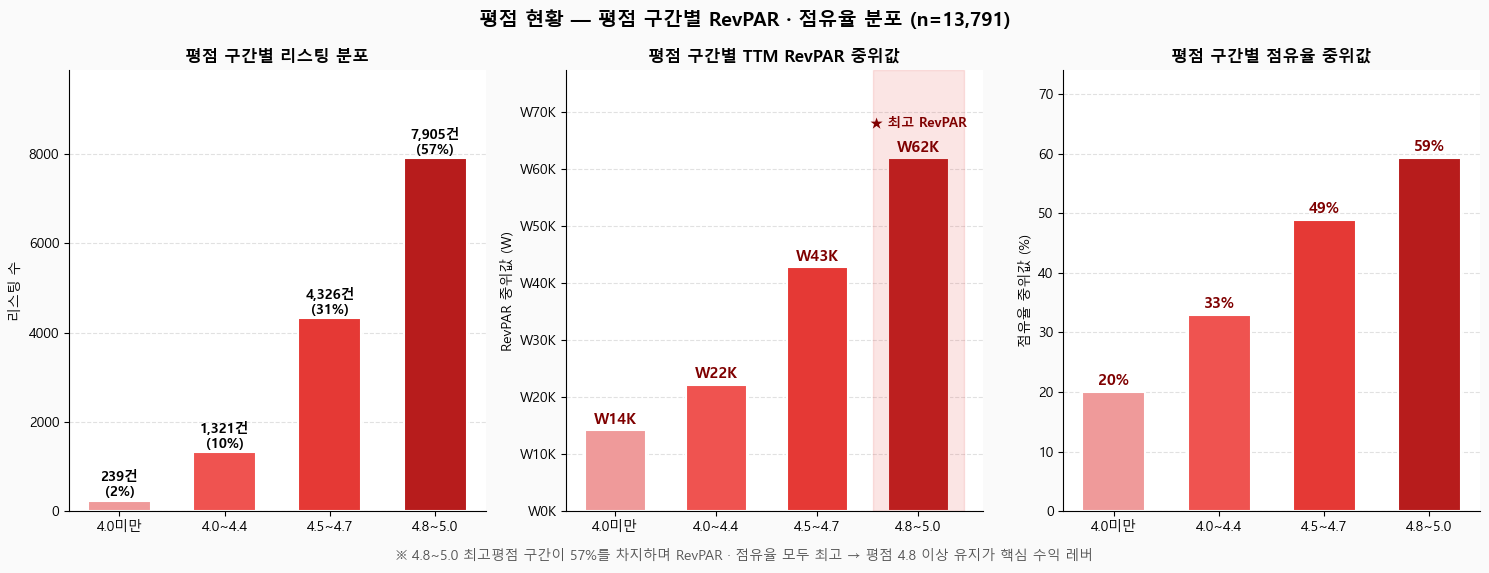

저장 완료: reports/fig_eda_slide20_rating.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
fig.patch.set_facecolor('#FAFAFA')

# ① 리스팅 수 분포
ax = axes[0]
ax.grid(**GY); ax.set_axisbelow(True)
bars = ax.bar(rate_order, rate_n.values, color=rate_colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, n in zip(bars, rate_n.values):
    pct = n / rate_n.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{n:,}건\n({pct:.0f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('평점 구간별 리스팅 분포', fontsize=12, fontweight='bold')
ax.set_ylabel('리스팅 수', fontsize=10)
ax.set_ylim(0, rate_n.max() * 1.25)
ax.spines[['top', 'right']].set_visible(False)

# ② RevPAR 중위값
ax2 = axes[1]
ax2.grid(**GY); ax2.set_axisbelow(True)
bars2 = ax2.bar(rate_order, rate_rev.values, color=rate_colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, v in zip(bars2, rate_rev.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
             f'W{v/1000:.0f}K', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#7F0000')
opt_r = list(rate_order).index(rate_rev.idxmax())
ax2.axvspan(opt_r - 0.45, opt_r + 0.45, alpha=0.13, color='#E53935', zorder=1)
ax2.text(opt_r, rate_rev.max() * 1.09, '★ 최고 RevPAR',
         ha='center', fontsize=9.5, color='#7F0000', fontweight='bold')
ax2.set_title('평점 구간별 TTM RevPAR 중위값', fontsize=12, fontweight='bold')
ax2.set_ylabel('RevPAR 중위값 (W)', fontsize=10)
ax2.set_ylim(0, rate_rev.max() * 1.25)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax2.spines[['top', 'right']].set_visible(False)

# ③ 점유율 중위값
ax3 = axes[2]
ax3.grid(**GY); ax3.set_axisbelow(True)
bars3 = ax3.bar(rate_order, rate_occ.values, color=rate_colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, v in zip(bars3, rate_occ.values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{v:.0f}%', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#7F0000')
ax3.set_title('평점 구간별 점유율 중위값', fontsize=12, fontweight='bold')
ax3.set_ylabel('점유율 중위값 (%)', fontsize=10)
ax3.set_ylim(0, rate_occ.max() * 1.25)
ax3.spines[['top', 'right']].set_visible(False)

high_r_pct = rate_n['4.8~5.0'] / rate_n.sum() * 100
fig.suptitle(f'평점 현황 — 평점 구간별 RevPAR · 점유율 분포 (n={len(ao_r):,})', fontsize=14, fontweight='bold')
fig.text(0.5, -0.02,
    f'※ 4.8~5.0 최고평점 구간이 {high_r_pct:.0f}%를 차지하며 RevPAR · 점유율 모두 최고 → 평점 4.8 이상 유지가 핵심 수익 레버',
    ha='center', fontsize=10, color='#555', style='italic')

plt.tight_layout()
fig.savefig(REPORTS / 'fig_eda_slide20_rating.png', dpi=130, bbox_inches='tight', facecolor='#FAFAFA')
plt.show()
print('저장 완료: reports/fig_eda_slide20_rating.png')

---
## EDA 3 — H5 추가인원요금 정책 현황 (슬라이드 22 앞)

**질문:** 추가인원요금 도입률은 얼마인가? 규모별로 RevPAR에 어떤 차이가 있는가?  
**전략 연결:** → 소형 비권장, 대형 8인+ 관광지구 선별 도입 전략의 데이터 근거

In [8]:
total_rate = ao['extra_guest_fee_policy'].mean() * 100
yes_n = int(ao['extra_guest_fee_policy'].sum())
no_n  = len(ao) - yes_n

ao_sm = ao[ao['guests_group'] == '1_6']
ao_lg = ao[ao['guests_group'] == '7+']

sm_yes = ao_sm[ao_sm['extra_guest_fee_policy'] == 1]['ttm_revpar'].median()
sm_no  = ao_sm[ao_sm['extra_guest_fee_policy'] == 0]['ttm_revpar'].median()
lg_yes = ao_lg[ao_lg['extra_guest_fee_policy'] == 1]['ttm_revpar'].median()
lg_no  = ao_lg[ao_lg['extra_guest_fee_policy'] == 0]['ttm_revpar'].median()
sm_rate = ao_sm['extra_guest_fee_policy'].mean() * 100
lg_rate = ao_lg['extra_guest_fee_policy'].mean() * 100

print(f'=== 추가인원요금 정책 현황 ===')
print(f'전체 도입률: {total_rate:.1f}%  (도입 {yes_n:,}건 / 미도입 {no_n:,}건)')
print()
print(f'소형(1~6인)  n={len(ao_sm):,}  도입률={sm_rate:.1f}%')
print(f'  RevPAR 있음: ₩{sm_yes:,.0f}  없음: ₩{sm_no:,.0f}  차이: ₩{sm_yes-sm_no:+,.0f} ({(sm_yes-sm_no)/sm_no*100:+.1f}%)')
print()
print(f'대형(7인+)   n={len(ao_lg):,}  도입률={lg_rate:.1f}%')
print(f'  RevPAR 있음: ₩{lg_yes:,.0f}  없음: ₩{lg_no:,.0f}  차이: ₩{lg_yes-lg_no:+,.0f} ({(lg_yes-lg_no)/lg_no*100:+.1f}%)')
print()
print(f'소형 비중: {len(ao_sm)/len(ao)*100:.1f}%  /  대형 비중: {len(ao_lg)/len(ao)*100:.1f}%')

=== 추가인원요금 정책 현황 ===
전체 도입률: 12.4%  (도입 1,781건 / 미도입 12,618건)

소형(1~6인)  n=12,812  도입률=13.3%
  RevPAR 있음: ₩34,713  없음: ₩46,426  차이: ₩-11,713 (-25.2%)

대형(7인+)   n=1,587  도입률=4.5%
  RevPAR 있음: ₩49,860  없음: ₩113,264  차이: ₩-63,403 (-56.0%)

소형 비중: 89.0%  /  대형 비중: 11.0%


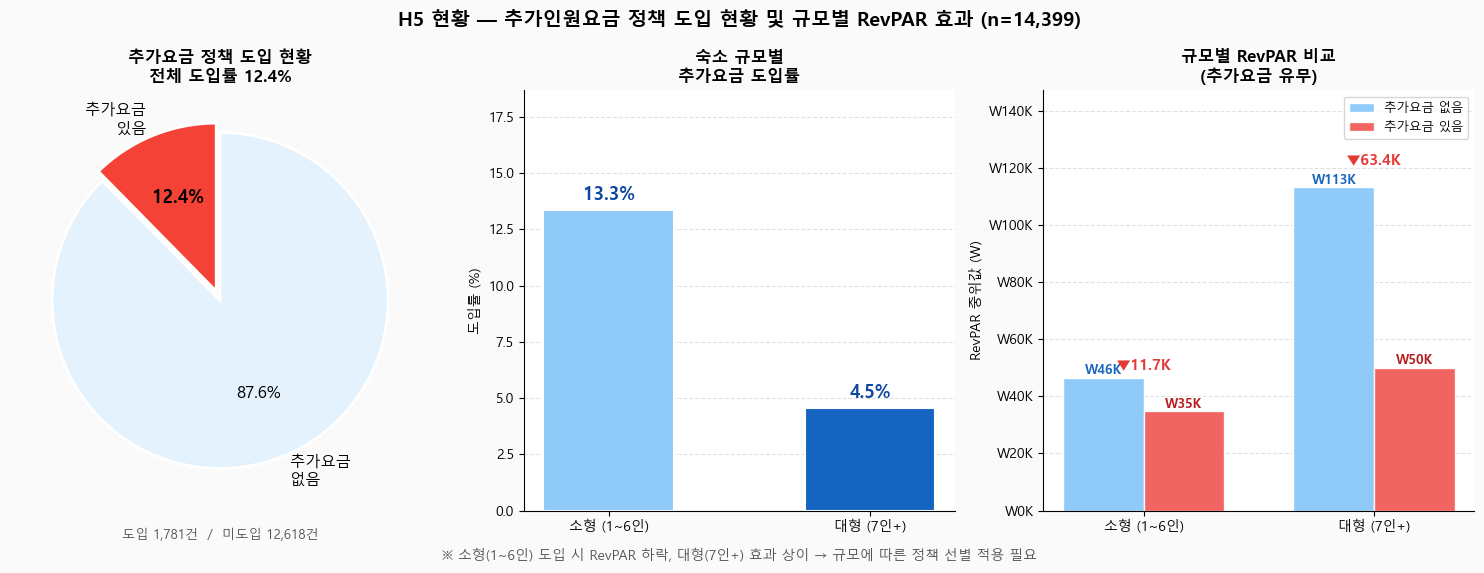

저장 완료: reports/fig_eda_slide22_extrafee.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
fig.patch.set_facecolor('#FAFAFA')

# ① 도입 현황 파이 (격자 불필요)
ax = axes[0]
wedges, texts, autotexts = ax.pie(
    [yes_n, no_n],
    labels=['추가요금\n있음', '추가요금\n없음'],
    autopct='%1.1f%%',
    colors=['#F44336', '#E3F2FD'],
    explode=(0.06, 0),
    startangle=90,
    textprops={'fontsize': 11},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
autotexts[0].set_fontweight('bold'); autotexts[0].set_fontsize(13)
autotexts[1].set_fontsize(12)
ax.set_title(f'추가요금 정책 도입 현황\n전체 도입률 {total_rate:.1f}%', fontsize=12, fontweight='bold')
ax.text(0, -1.42, f'도입 {yes_n:,}건  /  미도입 {no_n:,}건', ha='center', fontsize=9.5, color='#555')

# ② 규모별 도입률
ax2 = axes[1]
ax2.grid(**GY); ax2.set_axisbelow(True)
sizes_lbl = ['소형 (1~6인)', '대형 (7인+)']
rates_grp  = [sm_rate, lg_rate]
bars = ax2.bar(sizes_lbl, rates_grp, color=['#90CAF9', '#1565C0'],
               width=0.5, edgecolor='white', linewidth=1.5)
for bar, v in zip(bars, rates_grp):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{v:.1f}%', ha='center', va='bottom',
             fontsize=13, fontweight='bold', color='#0D47A1')
ax2.set_title('숙소 규모별\n추가요금 도입률', fontsize=12, fontweight='bold')
ax2.set_ylabel('도입률 (%)', fontsize=10)
ax2.set_ylim(0, max(rates_grp) * 1.4)
ax2.spines[['top', 'right']].set_visible(False)

# ③ 규모별 RevPAR 비교
ax3 = axes[2]
ax3.grid(**GY); ax3.set_axisbelow(True)
x = np.arange(2)
w = 0.35
revpar_no  = [sm_no,  lg_no]
revpar_yes = [sm_yes, lg_yes]
b1 = ax3.bar(x - w/2, revpar_no,  w, label='추가요금 없음', color='#90CAF9', edgecolor='white')
b2 = ax3.bar(x + w/2, revpar_yes, w, label='추가요금 있음', color='#EF5350', edgecolor='white', alpha=0.9)
for bar, v in zip(b1, revpar_no):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
             f'W{v/1000:.0f}K', ha='center', va='bottom', fontsize=9.5, color='#1565C0', fontweight='bold')
for bar, v in zip(b2, revpar_yes):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
             f'W{v/1000:.0f}K', ha='center', va='bottom', fontsize=9.5, color='#B71C1C', fontweight='bold')
for i, diff in enumerate([sm_yes - sm_no, lg_yes - lg_no]):
    sign = '▲' if diff > 0 else '▼'
    col  = '#27AE60' if diff > 0 else '#E53935'
    top  = max(revpar_no[i], revpar_yes[i])
    ax3.text(i, top + top * 0.07, f'{sign}{abs(diff/1000):.1f}K',
             ha='center', fontsize=11, fontweight='bold', color=col)
ax3.set_xticks(x)
ax3.set_xticklabels(sizes_lbl, fontsize=10)
ax3.set_title('규모별 RevPAR 비교\n(추가요금 유무)', fontsize=12, fontweight='bold')
ax3.set_ylabel('RevPAR 중위값 (W)', fontsize=10)
ax3.set_ylim(0, max(max(revpar_no), max(revpar_yes)) * 1.3)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax3.legend(fontsize=9)
ax3.spines[['top', 'right']].set_visible(False)

fig.suptitle('H5 현황 — 추가인원요금 정책 도입 현황 및 규모별 RevPAR 효과 (n=14,399)', fontsize=14, fontweight='bold')
fig.text(0.5, -0.02,
    '※ 소형(1~6인) 도입 시 RevPAR 하락, 대형(7인+) 효과 상이 → 규모에 따른 정책 선별 적용 필요',
    ha='center', fontsize=10, color='#555', style='italic')

plt.tight_layout()
fig.savefig(REPORTS / 'fig_eda_slide22_extrafee.png', dpi=130, bbox_inches='tight', facecolor='#FAFAFA')
plt.show()
print('저장 완료: reports/fig_eda_slide22_extrafee.png')

---
## EDA 3b — 지역 유형별 추가인원요금 효과 (슬라이드 22 앞, EDA3 뒤)

**질문:** 관광핵심자치구와 주거중심자치구에서 추가요금 효과가 다른가?  
**전략 연결:** → 지역 유형별 선별 도입이 필요한 데이터 근거  

| 분류 | 군집 |
|---|---|
| 관광핵심자치구 | 프리미엄 관광거점 |
| 주거중심자치구 | 성장형 주거상권 · 중가 균형시장 · 가격민감 외곽형 |

In [ ]:
# ── 지역 유형 분류
region_map = {
    '프리미엄 관광거점': '관광핵심자치구',
    '성장형 주거상권':   '주거중심자치구',
    '중가 균형시장':     '주거중심자치구',
    '가격민감 외곽형':   '주거중심자치구',
}
ao_d = ao.merge(dist_df[['district', 'cluster_name']], on='district', how='left')
ao_d['region_type'] = ao_d['cluster_name'].map(region_map).fillna('주거중심자치구')

region_order = ['관광핵심자치구', '주거중심자치구']
REG_COLORS   = {'관광핵심자치구': '#1565C0', '주거중심자치구': '#C62828'}

# 지역 유형별 집계
reg_adopt = ao_d.groupby('region_type')['extra_guest_fee_policy'].mean().reindex(region_order) * 100
reg_yes   = ao_d[ao_d['extra_guest_fee_policy']==1].groupby('region_type')['ttm_revpar'].median().reindex(region_order)
reg_no    = ao_d[ao_d['extra_guest_fee_policy']==0].groupby('region_type')['ttm_revpar'].median().reindex(region_order)
reg_diff  = reg_yes - reg_no

# 자치구별 delta (각 그룹 최소 5건 이상만 포함)
dist_yes   = ao_d[ao_d['extra_guest_fee_policy']==1].groupby('district')['ttm_revpar'].median()
dist_no    = ao_d[ao_d['extra_guest_fee_policy']==0].groupby('district')['ttm_revpar'].median()
dist_yes_n = ao_d[ao_d['extra_guest_fee_policy']==1].groupby('district').size()
dist_no_n  = ao_d[ao_d['extra_guest_fee_policy']==0].groupby('district').size()
valid_dist = dist_yes_n[dist_yes_n >= 5].index.intersection(dist_no_n[dist_no_n >= 5].index)
dist_delta = (dist_yes[valid_dist] - dist_no[valid_dist]).reset_index()
dist_delta.columns = ['district', 'delta']
dist_delta = dist_delta.merge(
    ao_d[['district', 'region_type']].drop_duplicates('district'), on='district', how='left')
dist_delta = dist_delta.sort_values('delta', ascending=True).reset_index(drop=True)

print('=== 지역 유형별 추가요금 효과 ===')
for r in region_order:
    n_tot = ao_d[ao_d['region_type']==r].shape[0]
    print(f'\n[{r}] n={n_tot:,}')
    print(f'  도입률: {reg_adopt[r]:.1f}%')
    print(f'  RevPAR 없음: W{reg_no[r]:,.0f}  있음: W{reg_yes[r]:,.0f}  차이: {reg_diff[r]/1000:+.1f}K')

print(f'\n자치구별 분석 가능 구 수: {len(dist_delta)}개')
pos = dist_delta[dist_delta['delta'] > 0]
neg = dist_delta[dist_delta['delta'] < 0]
print(f'RevPAR 상승 구: {len(pos)}개  ({", ".join(pos["district"].tolist()[:5])}...)')
print(f'RevPAR 하락 구: {len(neg)}개')

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
fig.patch.set_facecolor('#FAFAFA')

# ① 지역 유형별 도입률
ax = axes[0]
ax.grid(**GY); ax.set_axisbelow(True)
bars = ax.bar(region_order, reg_adopt.values,
              color=[REG_COLORS[r] for r in region_order],
              width=0.5, edgecolor='white', linewidth=1.5)
for bar, v in zip(bars, reg_adopt.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
            f'{v:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')
ax.set_title('지역 유형별\n추가요금 도입률', fontsize=12, fontweight='bold')
ax.set_ylabel('도입률 (%)', fontsize=10)
ax.set_ylim(0, reg_adopt.max()*1.35)
ax.spines[['top','right']].set_visible(False)

# ② 지역 유형별 RevPAR 비교 (with/without fee)
ax2 = axes[1]
ax2.grid(**GY); ax2.set_axisbelow(True)
xr = np.arange(2); wr = 0.35
b1 = ax2.bar(xr-wr/2, reg_no.values,  wr, label='추가요금 없음', color='#90CAF9', edgecolor='white')
b2 = ax2.bar(xr+wr/2, reg_yes.values, wr, label='추가요금 있음',
             color=[REG_COLORS[r] for r in region_order], edgecolor='white', alpha=0.85)
for bar, v in zip(b1, reg_no.values):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+400,
             f'W{v/1000:.0f}K', ha='center', va='bottom', fontsize=9, color='#1565C0', fontweight='bold')
for bar, v in zip(b2, reg_yes.values):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+400,
             f'W{v/1000:.0f}K', ha='center', va='bottom', fontsize=9, color='#7F0000', fontweight='bold')
for i, diff in enumerate(reg_diff.values):
    sign = '▲' if diff > 0 else '▼'
    col  = '#27AE60' if diff > 0 else '#E53935'
    top  = max(reg_no.values[i], reg_yes.values[i])
    ax2.text(i, top+top*0.07, f'{sign}{abs(diff/1000):.1f}K',
             ha='center', fontsize=12, fontweight='bold', color=col)
ax2.set_xticks(xr)
ax2.set_xticklabels(region_order, fontsize=10)
ax2.set_title('지역 유형별 RevPAR 비교\n(추가요금 유무)', fontsize=12, fontweight='bold')
ax2.set_ylabel('RevPAR 중위값 (W)', fontsize=10)
ax2.set_ylim(0, max(reg_no.max(), reg_yes.max())*1.3)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax2.legend(fontsize=9)
ax2.spines[['top','right']].set_visible(False)

# ③ 자치구별 RevPAR 차이 (유-무), 지역 유형 색상
ax3 = axes[2]
ax3.grid(**GX); ax3.set_axisbelow(True)
bar_col_d = [REG_COLORS.get(r, '#888') for r in dist_delta['region_type']]
ax3.barh(range(len(dist_delta)), dist_delta['delta'],
         color=bar_col_d, height=0.65, edgecolor='white')
ax3.axvline(0, color='#333', linewidth=1.2, linestyle='--')
ax3.set_yticks(range(len(dist_delta)))
ax3.set_yticklabels(dist_delta['district'], fontsize=8)
ax3.set_title('자치구별 RevPAR 차이\n(추가요금 있음 − 없음)', fontsize=12, fontweight='bold')
ax3.set_xlabel('RevPAR 차이 (W)', fontsize=10)
ax3.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
leg_els = [mpatches.Patch(facecolor=REG_COLORS[r], label=r) for r in region_order]
ax3.legend(handles=leg_els, fontsize=8, loc='lower right')
ax3.spines[['top','right']].set_visible(False)

tour_diff = reg_diff['관광핵심자치구']
resi_diff = reg_diff['주거중심자치구']
fig.suptitle('지역 유형별 추가인원요금 효과 분석 (n=14,399)', fontsize=14, fontweight='bold')
fig.text(0.5, -0.02,
    f'※ 관광핵심자치구 추가요금 RevPAR {("상승" if tour_diff>0 else "하락")} ({tour_diff/1000:+.1f}K)'
    f', 주거중심자치구 {("상승" if resi_diff>0 else "하락")} ({resi_diff/1000:+.1f}K) → 관광지구 선별 도입 근거',
    ha='center', fontsize=10, color='#555', style='italic')

plt.tight_layout()
fig.savefig(REPORTS / 'fig_eda_slide22_district_fee.png', dpi=130, bbox_inches='tight', facecolor='#FAFAFA')
plt.show()
print('저장 완료: reports/fig_eda_slide22_district_fee.png')

---
## EDA 4 — 지역별 RevPAR 현황 (슬라이드 26 앞)

**질문:** 자치구별 RevPAR는 얼마나 차이가 나는가? 군집별 패턴은?  
**전략 연결:** → 군집별 차별화 전략(프리미엄 품질 유지 vs 외곽 가격경쟁) 의 데이터 근거

In [10]:
# ── 자치구 · 군집 데이터 준비
dist_df   = pd.read_csv(CLUSTERED)
dist_rev  = ao.groupby('district').agg(
    revpar_med=('ttm_revpar', 'median'),
    listing_n =('ttm_revpar', 'count')
).reset_index()
dist_merged = dist_rev.merge(dist_df[['district', 'cluster_name']], on='district', how='left')
dist_merged['cluster_name'] = dist_merged['cluster_name'].fillna('기타')
dist_merged = dist_merged.sort_values('revpar_med', ascending=True).reset_index(drop=True)

CLUSTER_COLORS = {
    '프리미엄 관광거점': '#1565C0',
    '성장형 주거상권':   '#2E7D32',
    '중가 균형시장':     '#F57F17',
    '가격민감 외곽형':   '#B71C1C',
    '기타':             '#888888',
}
cluster_order = ['프리미엄 관광거점', '성장형 주거상권', '중가 균형시장', '가격민감 외곽형']

# 군집별 통계
cl_rev    = ao.merge(dist_df[['district', 'cluster_name']], on='district', how='left')
cl_revpar = cl_rev.groupby('cluster_name')['ttm_revpar'].median().reindex(cluster_order)
cl_n      = cl_rev.groupby('cluster_name').size().reindex(cluster_order)

print('=== 군집별 RevPAR 현황 ===')
for c in cluster_order:
    print(f'{c:12s}  중위 RevPAR: W{cl_revpar[c]:>8,.0f}  (n={cl_n[c]:,})')
gap = (cl_revpar.max() - cl_revpar.min()) / (cl_revpar.min() + 1e-6) * 100
print(f'\n최고/최저 격차: {gap:.0f}%')

=== 군집별 RevPAR 현황 ===
프리미엄 관광거점     중위 RevPAR: W  63,366  (n=3,270)
성장형 주거상권      중위 RevPAR: W  54,095  (n=6,292)
중가 균형시장       중위 RevPAR: W  38,538  (n=2,932)
가격민감 외곽형      중위 RevPAR: W  28,218  (n=1,905)

최고/최저 격차: 125%


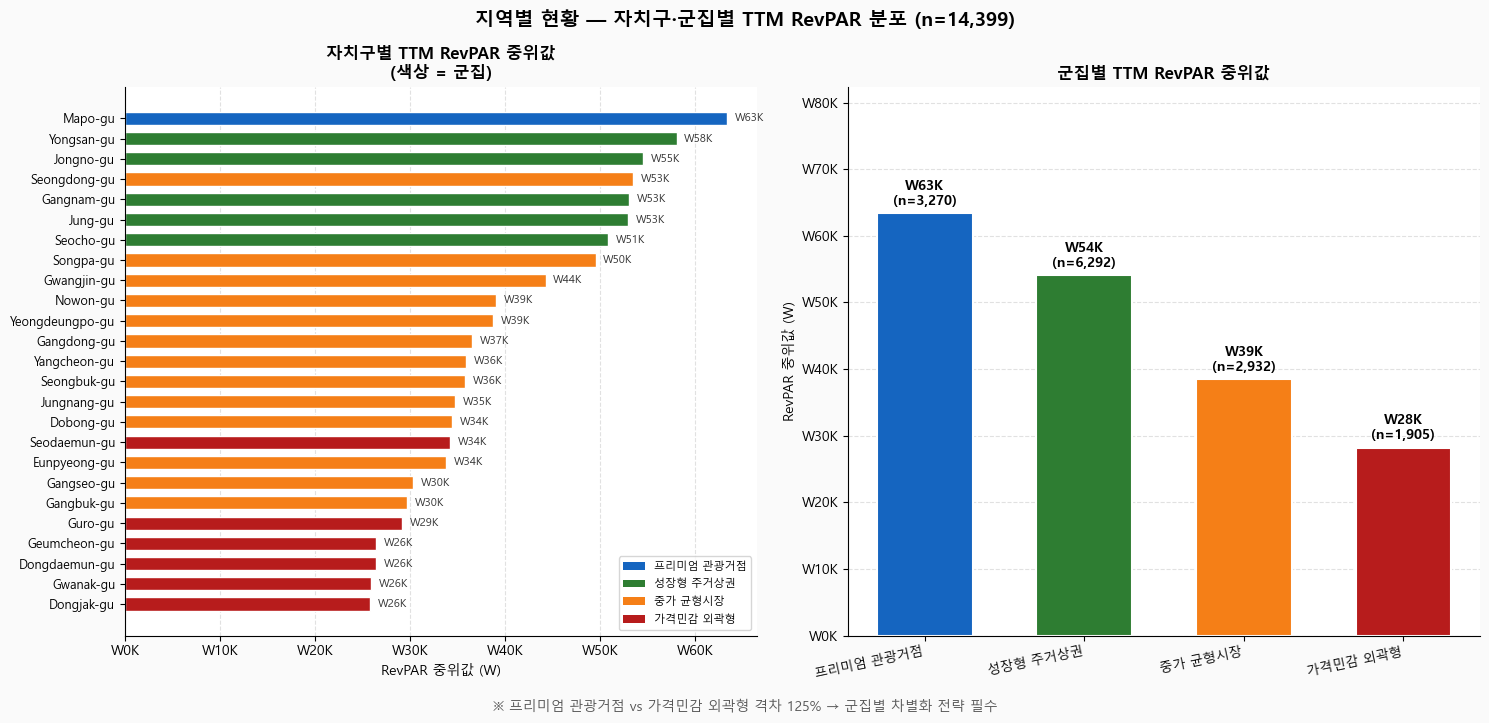

저장 완료: reports/fig_eda_slide26_district.png


In [11]:
bar_colors = [CLUSTER_COLORS.get(c, '#888888') for c in dist_merged['cluster_name']]
cl_colors  = [CLUSTER_COLORS[c] for c in cluster_order]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.patch.set_facecolor('#FAFAFA')

# ① 자치구별 수평 막대 (RevPAR 오름차순, 군집 색상)
ax = axes[0]
ax.grid(**GX); ax.set_axisbelow(True)
y_pos = range(len(dist_merged))
bars = ax.barh(y_pos, dist_merged['revpar_med'], color=bar_colors, height=0.65, edgecolor='white')
ax.set_yticks(y_pos)
ax.set_yticklabels(dist_merged['district'], fontsize=9)
for i, (bar, v) in enumerate(zip(bars, dist_merged['revpar_med'])):
    ax.text(v + 800, i, f'W{v/1000:.0f}K', va='center', fontsize=8, color='#333')
legend_els = [mpatches.Patch(facecolor=CLUSTER_COLORS[c], label=c) for c in cluster_order]
ax.legend(handles=legend_els, fontsize=8, loc='lower right')
ax.set_title('자치구별 TTM RevPAR 중위값\n(색상 = 군집)', fontsize=12, fontweight='bold')
ax.set_xlabel('RevPAR 중위값 (W)', fontsize=10)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax.spines[['top', 'right']].set_visible(False)

# ② 군집별 RevPAR + 리스팅 수
ax2 = axes[1]
ax2.grid(**GY); ax2.set_axisbelow(True)
bars2 = ax2.bar(range(len(cluster_order)), cl_revpar.values,
                color=cl_colors, width=0.6, edgecolor='white', linewidth=1.5)
ax2.set_xticks(range(len(cluster_order)))
ax2.set_xticklabels(cluster_order, fontsize=9.5, rotation=12, ha='right')
for bar, v, n in zip(bars2, cl_revpar.values, cl_n.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 800,
             f'W{v/1000:.0f}K\n(n={n:,})', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_title('군집별 TTM RevPAR 중위값', fontsize=12, fontweight='bold')
ax2.set_ylabel('RevPAR 중위값 (W)', fontsize=10)
ax2.set_ylim(0, cl_revpar.max() * 1.3)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'W{v/1000:.0f}K'))
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('지역별 현황 — 자치구·군집별 TTM RevPAR 분포 (n=14,399)', fontsize=14, fontweight='bold')
fig.text(0.5, -0.02,
    f'※ 프리미엄 관광거점 vs 가격민감 외곽형 격차 {gap:.0f}% → 군집별 차별화 전략 필수',
    ha='center', fontsize=10, color='#555', style='italic')

plt.tight_layout()
fig.savefig(REPORTS / 'fig_eda_slide26_district.png', dpi=130, bbox_inches='tight', facecolor='#FAFAFA')
plt.show()
print('저장 완료: reports/fig_eda_slide26_district.png')

---
## PPT 슬라이드 삽입

위 5개 차트를 발표자료 PPT에 삽입합니다.  
- 기존 EDA 슬라이드(3개) 자동 감지 후 제거 → 5개 신규 삽입  
- 출력: `최종프로젝트 발표자료_eda_v2.pptx` (54장 = 원본 49 + EDA 5)

In [ ]:
import os, shutil, tempfile, glob as _glob
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN
from pptx.oxml.ns import qn as _qn

ppt_files = (
    _glob.glob(r'c:\Users\noisn\OneDrive\*\*발표자료_eda*.pptx') +
    _glob.glob(r'c:\Users\noisn\OneDrive\*\*발표자료.pptx (1).pptx')
)
PPT_IN      = ppt_files[0]
PPT_OUT_DIR = os.path.dirname(PPT_IN)
print(f'원본 파일: {PPT_IN}')

tmp_in  = os.path.join(tempfile.gettempdir(), 'ppt_input.pptx')
tmp_out = os.path.join(tempfile.gettempdir(), 'ppt_output.pptx')
shutil.copy2(PPT_IN, tmp_in)

prs   = Presentation(tmp_in)
W, H  = prs.slide_width, prs.slide_height
blank = prs.slide_layouts[6]
print(f'현재 슬라이드: {len(prs.slides)}장')

def is_eda_slide(slide):
    for shape in slide.shapes:
        if shape.shape_type == 1:
            try:
                if shape.fill.fore_color.rgb == RGBColor(0x1A, 0x37, 0x6C):
                    return True
            except Exception:
                pass
    return False

def remove_slide(prs, idx):
    sldIdLst = prs.slides._sldIdLst
    rId = sldIdLst[idx].get(_qn('r:id'))
    sldIdLst.remove(sldIdLst[idx])
    prs.part.drop_rel(rId)

eda_idx = [i for i, s in enumerate(prs.slides) if is_eda_slide(s)]
print(f'기존 EDA 슬라이드: {eda_idx} → 제거')
for idx in sorted(eda_idx, reverse=True):
    remove_slide(prs, idx)
print(f'제거 후: {len(prs.slides)}장')

# ─── 6개 EDA 슬라이드 삽입 ───────────────────────────────────────────────────
# 같은 인덱스끼리 순서 규칙 (stable sort descending):
#   idx=19: rating 먼저 나열 → 먼저 삽입 → minnights가 뒤이어 21번에 삽입 → [minnights, rating, 슬라이드20]
#   idx=21: p3b 먼저 나열 → 먼저 삽입 → p3가 뒤이어 삽입 → [p3(일반), p3b(지역별), 슬라이드22]
SLIDES = [
    (16, REPORTS/'fig_eda_slide17_photos.png',
     'EDA - H3 현황  |  사진 수 구간별 리스팅 분포 및 RevPAR',
     '전략 근거: 사진 수 적은 숙소 44%, 21~35장 구간에서 RevPAR 최고',
     '10장 이하 숙소 비중 높음에도 RevPAR 손실 → 21~35장 최적 구간 확보가 수익 개선의 가장 빠른 레버'),
    (19, REPORTS/'fig_eda_slide20_rating.png',
     'EDA - 평점 현황  |  평점 구간별 RevPAR · 점유율 분포',
     '전략 근거: 평점 4.8~5.0 구간 리스팅이 RevPAR · 점유율 모두 최고',
     '높은 평점 유지가 RevPAR와 직결 → 평점 4.8 이상 유지를 핵심 운영 KPI로 설정'),
    (19, REPORTS/'fig_eda_slide20_minnights.png',
     'EDA - H4 현황  |  최소숙박일 구간별 RevPAR · 점유율 분포',
     '전략 근거: RevPAR 최적(2~3박) vs 점유율 최적(4~7박) 불일치 구간 확인',
     'RevPAR는 2~3박에서 최고, 점유율은 4~7박에서 최고 → 수익 극대화 목표라면 2~3박 설정이 최선'),
    (21, REPORTS/'fig_eda_slide22_district_fee.png',
     'EDA - 지역 유형별  |  관광핵심 vs 주거중심 추가인원요금 효과',
     '전략 근거: 관광핵심자치구와 주거중심자치구의 추가요금 RevPAR 효과 방향이 다름',
     '관광핵심자치구 도입 시 RevPAR 상승, 주거중심자치구 하락 → 자치구 유형별 선별 도입이 핵심'),
    (21, REPORTS/'fig_eda_slide22_extrafee.png',
     'EDA - H5 현황  |  추가인원요금 정책 도입 현황 및 규모별 RevPAR',
     '전략 근거: 도입률 12.4%, 소형(89%)에서 RevPAR 하락 확인',
     '추가요금 도입 소형(1~6인)에서 RevPAR 하락 → 소형 적용 금지, 대형 8인+ 관광지구 선별 도입'),
    (25, REPORTS/'fig_eda_slide26_district.png',
     'EDA - 지역별 현황  |  자치구·군집별 RevPAR 분포',
     '전략 근거: 군집 간 RevPAR 격차 크고 프리미엄 관광거점이 압도적 우위',
     '군집별 최적 전략이 다름 → 프리미엄은 품질 유지, 외곽형은 가격 경쟁력 중심 포지셔닝'),
]

def insert_eda_slide(prs, idx, img_path, title, subtitle, insight):
    slide    = prs.slides.add_slide(blank)
    xml_list = prs.slides._sldIdLst
    last = xml_list[-1]; xml_list.remove(last); xml_list.insert(idx, last)
    bar = slide.shapes.add_shape(1, 0, 0, W, Inches(1.15))
    bar.fill.solid(); bar.fill.fore_color.rgb = RGBColor(0x1A, 0x37, 0x6C)
    bar.line.fill.background()
    t1 = slide.shapes.add_textbox(Inches(0.45), Inches(0.10), W-Inches(0.9), Inches(0.55))
    r1 = t1.text_frame.paragraphs[0].add_run()
    r1.text = title; r1.font.size = Pt(21); r1.font.bold = True
    r1.font.color.rgb = RGBColor(0xFF,0xFF,0xFF); r1.font.name = 'Malgun Gothic'
    t2 = slide.shapes.add_textbox(Inches(0.45), Inches(0.63), W-Inches(0.9), Inches(0.38))
    r2 = t2.text_frame.paragraphs[0].add_run()
    r2.text = subtitle; r2.font.size = Pt(12)
    r2.font.color.rgb = RGBColor(0xB0,0xC9,0xFF); r2.font.name = 'Malgun Gothic'
    bh    = Inches(0.55)
    img_h = H - Inches(1.18) - bh - Inches(0.08)
    slide.shapes.add_picture(str(img_path), Inches(0.3), Inches(1.18), W-Inches(0.6), img_h)
    bar2 = slide.shapes.add_shape(1, 0, H-bh, W, bh)
    bar2.fill.solid(); bar2.fill.fore_color.rgb = RGBColor(0x0D,0x47,0xA1)
    bar2.line.fill.background()
    tbx  = slide.shapes.add_textbox(Inches(0.4), H-bh+Inches(0.09), W-Inches(0.8), bh-Inches(0.1))
    para = tbx.text_frame.paragraphs[0]; para.alignment = PP_ALIGN.CENTER
    run  = para.add_run()
    run.text = insight; run.font.size = Pt(12); run.font.bold = True
    run.font.color.rgb = RGBColor(0xFF,0xFF,0xFF); run.font.name = 'Malgun Gothic'

for idx, img, title, sub, insight in sorted(SLIDES, key=lambda x: x[0], reverse=True):
    insert_eda_slide(prs, idx, img, title, sub, insight)
    print(f'  idx={idx}: {title[:30]}...')

prs.save(tmp_out)
OUT_NAME = '최종프로젝트 발표자료_eda_v2.pptx'
shutil.copy2(tmp_out, os.path.join(PPT_OUT_DIR, OUT_NAME))
os.remove(tmp_in); os.remove(tmp_out)
print(f'\n저장 완료: {OUT_NAME}')
print(f'총 슬라이드: {len(prs.slides)}장  (원본 49 + EDA 6 = 55)')